<a href="https://colab.research.google.com/github/tommihab/CNN-LSTM-discharge-forecasting-of-the-Darling-River-/blob/main/Raster_Processing_CNN_LSTM_Bourke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This is the data preprocessing python notebook of the study "Dual-Input CNN-LSTM for river discharge forecasting of the Darling River, Australia, using gridded Hydro-Meteorological data"

# NOTE: file import paths do not work as the original data is not made available by the author. Additionally, please note that certain code cells were executed iteratively for different datasets.
# To keep the notebook clean and avoid redundant code, not every sequential step for each individual dataset is shown here.

In [ ]:
pip install xarray dask netcdf4 rioxarray geopandas shapely pyproj h5netcdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 25.8 MB/s eta 0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2025.12.0
    Uninstalling xarray-2025.12.0:
      Successfully uninstalled xarray-2025.12.0


In [ ]:
import xarray as xr
import dask
import rioxarray
import geopandas as gpd
import shapely
import pyproj

In [ ]:
import os
import glob
import xarray as xr
import rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Precipitation Raster
precip_Test = "/content/drive/MyDrive/Raster_Data_Australia/precip_clipped_full.nc"

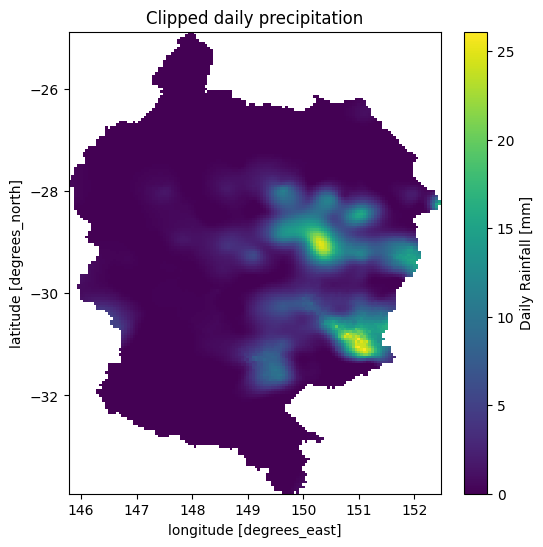

In [ ]:
# Plot precipitation for a selected time step

ds_precip_test = xr.open_dataset(precip_Test)
da_precip_test = ds_precip_test["rain_day"]

da_precip_test.isel(time=2520).plot(figsize=(6, 6))

plt.title("Daily precipitation")
plt.show()

In [ ]:
base_path = "/content/drive/MyDrive/Raster_Data_Australia/Precipitation_Raster_AUS"

In [ ]:
# Find all NetCDF files

files = glob.glob(base_path + "/*.nc")

print("Number of files:", len(files))

files[:5]

Anzahl Dateien: 0


[]

In [ ]:
!mkdir -p /content/data/precip
!cp /content/drive/MyDrive/Rainfall_Raster/Precipitation_Raster_AUS/*.nc /content/data/precip/

cp: cannot stat '/content/drive/MyDrive/Rainfall_Raster/Precipitation_Raster_AUS/*.nc': No such file or directory


In [ ]:
files_local = glob.glob("/content/data/precip/*.nc")

print("Lokale Dateien:", len(files_local))
files_local[:5]

Lokale Dateien: 54


['/content/data/precip/rain_day_2006.nc',
 '/content/data/precip/rain_day_2021.nc',
 '/content/data/precip/rain_day_2005.nc',
 '/content/data/precip/rain_day_1999.nc',
 '/content/data/precip/rain_day_2022.nc']

In [ ]:
ds_precip = xr.open_mfdataset(
    "/content/data/precip/*.nc",
    combine="by_coords",
    engine="h5netcdf",
    parallel=True
)

ds_precip

<xarray.Dataset> Size: 45GB
Dimensions:    (time: 19724, latitude: 681, longitude: 841)
Coordinates:
  * time       (time) datetime64[ns] 158kB 1971-01-01 1971-01-02 ... 2025-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0
Data variables:
    rain_day   (time, latitude, longitude) float32 45GB dask.array<chunksize=(16, 32, 32), meta=np.ndarray>
Attributes:
    var_name:       rain_day
    url:            http://www.bom.gov.au/water/landscape
    date_created:   2018-03-12T06:33:13
    source:         AWRA-L-v5
    date_modified:  2018-03-12T06:33:13
    summary:        Data produced by Bureau of Meteorology Australian Water R...
    title:          Australian Landscape Water Balance AWRA-L Model Version 5
    Conventions:    CF-1.6, ACDD-1.3
    institution:    Bureau of Meteorology
    email:          awrams@bom.gov.au

In [ ]:
print(list(ds_precip.data_vars))
print(ds_precip.dims)
print(ds_precip.coords)

['rain_day']
FrozenMappingWarningOnValuesAccess({'time': 19724, 'latitude': 681, 'longitude': 841})
Coordinates:
  * time       (time) datetime64[ns] 158kB 1971-01-01 1971-01-02 ... 2025-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0


In [ ]:
da_precip = ds_precip["rain_day"]

In [ ]:
da_precip = da_precip.rename({
    "longitude": "x",
    "latitude": "y"
})

In [ ]:
da_precip = da_precip.rio.write_crs("EPSG:4326")

In [ ]:
print(da_precip)
print(da_precip.rio.crs)

<xarray.DataArray 'rain_day' (time: 19724, y: 681, x: 841)> Size: 45GB
dask.array<concatenate, shape=(19724, 681, 841), dtype=float32, chunksize=(16, 32, 32), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 158kB 1971-01-01 ... 2025-12-31
  * y            (y) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * x            (x) float64 7kB 112.0 112.0 112.1 112.2 ... 153.9 153.9 154.0
    spatial_ref  int64 8B 0
Attributes:
    name:           rain_day
    standard_name:  lwe_thickness_of_precipitation_amount
    long_name:      Daily Rainfall
    source:         Interpolated surface observations
    units:          mm
EPSG:4326


In [ ]:
# Load Catchment as .shp file

import geopandas as gpd

shape_path = "/content/drive/MyDrive/Raster_Data_Australia/Bourke_Catchment_Area/Murray_Darling_PairwiseDisso.shp"

catchment = gpd.read_file(shape_path)
catchment.head()

,Shape_Leng,Shape_Area,geometry
0,4.520943e+06,5.100791e+11,"POLYGON ((16666964 -4019329, 16665751 -4018846..."


In [ ]:
catchment = catchment.to_crs(da_precip.rio.crs)

In [ ]:
da_precip_clip = da_precip.rio.clip(
    catchment.geometry,
    catchment.crs,
    drop=True
)

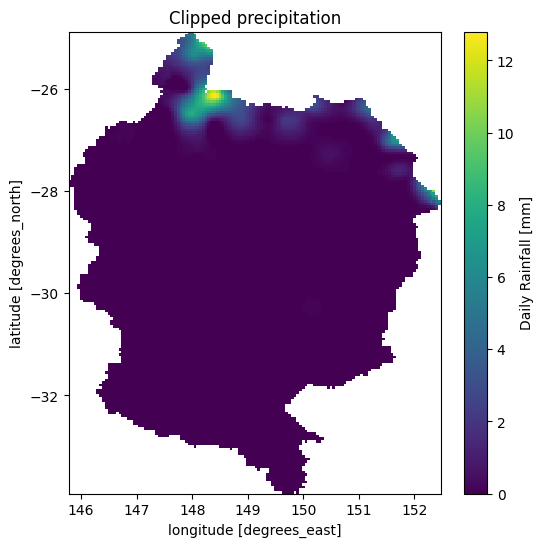

In [ ]:
# Plot clipped precipitation

da_precip_clip.isel(time=0).plot(figsize=(6, 6))

plt.title("Clipped precipitation")
plt.show()

In [ ]:
da_precip_clip

<xarray.DataArray 'rain_day' (time: 19724, y: 181, x: 134)> Size: 2GB
dask.array<getitem, shape=(19724, 181, 134), dtype=float32, chunksize=(16, 32, 32), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 158kB 1971-01-01 ... 2025-12-31
  * y            (y) float64 1kB -24.9 -24.95 -25.0 ... -33.8 -33.85 -33.9
  * x            (x) float64 1kB 145.8 145.8 145.9 145.9 ... 152.3 152.4 152.4
    spatial_ref  int64 8B 0
Attributes:
    name:           rain_day
    standard_name:  lwe_thickness_of_precipitation_amount
    long_name:      Daily Rainfall
    source:         Interpolated surface observations
    units:          mm

In [ ]:
from dask.diagnostics import ProgressBar

da_precip_clip = da_precip_clip.chunk({
    "time": 365,
    "y": 200,
    "x": 200
})

In [ ]:
from dask.diagnostics import ProgressBar

local_path = "/content/precip_clipped_full.nc"

encoding = {
    "rain_day": {
        "zlib": True,
        "complevel": 5
    }
}

print("Saving locally to:", local_path)

with ProgressBar():
    da_precip_clip.to_netcdf(local_path, encoding=encoding)

print("Local save completed.")

Speichere lokal nach: /content/precip_clipped_full.nc
[########################################] | 100% Completed | 13m 33s
Lokales Speichern abgeschlossen.


In [ ]:
# Copy the processed file to Google Drive

drive_path = "/content/drive/MyDrive/Rainfall_Raster/precip_clipped_full.nc"

!cp /content/precip_clipped_full.nc "$drive_path"

print("File copied to Google Drive.")

Datei nach Drive kopiert.


In [ ]:
# Inspect the saved precipitation dataset

ds = xr.open_dataset(drive_path)
print(ds)

da = ds["rain_day"]
print(da)

<xarray.Dataset> Size: 2GB
Dimensions:      (time: 19724, y: 181, x: 134)
Coordinates:
  * time         (time) datetime64[ns] 158kB 1971-01-01 ... 2025-12-31
  * y            (y) float64 1kB -24.9 -24.95 -25.0 ... -33.8 -33.85 -33.9
  * x            (x) float64 1kB 145.8 145.8 145.9 145.9 ... 152.3 152.4 152.4
Data variables:
    spatial_ref  int64 8B ...
    rain_day     (time, y, x) float32 2GB ...
<xarray.DataArray 'rain_day' (time: 19724, y: 181, x: 134)> Size: 2GB
[478385896 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 158kB 1971-01-01 1971-01-02 ... 2025-12-31
  * y        (y) float64 1kB -24.9 -24.95 -25.0 -25.05 ... -33.8 -33.85 -33.9
  * x        (x) float64 1kB 145.8 145.8 145.9 145.9 ... 152.3 152.3 152.4 152.4
Attributes:
    name:           rain_day
    standard_name:  lwe_thickness_of_precipitation_amount
    long_name:      Daily Rainfall
    source:         Interpolated surface observations
    units:          mm


In [ ]:
# Remove the local file

!rm /content/precip_clipped_full.nc

print("Local file deleted.")

In [ ]:
# Soil moisture Raster data

In [ ]:
!mkdir -p /content/data/sm
!cp /content/drive/MyDrive/Raster_Data_Australia/Soil_moisture_Raster_AUS/*.nc /content/data/sm/

In [ ]:
# Check soil moisture files

sm_files = sorted(glob.glob("/content/data/sm/*.nc"))

print("Number of soil moisture files:", len(sm_files))

sm_files[:5]

Anzahl SM-Dateien: 45


['/content/data/sm/sm_pct_1981.nc',
 '/content/data/sm/sm_pct_1982.nc',
 '/content/data/sm/sm_pct_1983.nc',
 '/content/data/sm/sm_pct_1984.nc',
 '/content/data/sm/sm_pct_1985.nc']

In [ ]:
# Open one soil moisture file for inspection

ds_sm_test = xr.open_dataset(sm_files[0], engine="h5netcdf")

ds_sm_test

<xarray.Dataset> Size: 836MB
Dimensions:    (time: 365, latitude: 681, longitude: 841)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1981-01-01 1981-01-02 ... 1981-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0
Data variables:
    sm_pct     (time, latitude, longitude) float32 836MB ...
Attributes:
    var_name:       sm_pct
    title:          Australian Landscape Water Balance AWRA-L Model
    Description:    This data is provided by the Bureau of Meteorology and ca...
    summary:        Data produced by Bureau of Meteorology Australian Water R...
    source:         AWRA-L
    date_created:   2021-09-19T23:42:44
    Conventions:    CF-1.6, ACDD-1.3
    institution:    Bureau of Meteorology
    email:          awrams@bom.gov.au
    url:            http://www.bom.gov.au/water/landscape
    date_modified:  2021-09-19T23:42:44

In [ ]:
# Inspect dataset structure

print(list(ds_sm_test.data_vars))
print(ds_sm_test.dims)
print(ds_sm_test.coords)

['sm_pct']
FrozenMappingWarningOnValuesAccess({'time': 365, 'latitude': 681, 'longitude': 841})
Coordinates:
  * time       (time) datetime64[ns] 3kB 1981-01-01 1981-01-02 ... 1981-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0


In [ ]:
# Open and combine all annual soil moisture files

ds_sm = xr.open_mfdataset(
    sm_files,
    combine="by_coords",
    engine="h5netcdf",
    parallel=False
)

ds_sm

<xarray.Dataset> Size: 38GB
Dimensions:    (time: 16436, latitude: 681, longitude: 841)
Coordinates:
  * time       (time) datetime64[ns] 131kB 1981-01-01 1981-01-02 ... 2025-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0
Data variables:
    sm_pct     (time, latitude, longitude) float32 38GB dask.array<chunksize=(32, 32, 32), meta=np.ndarray>
Attributes:
    var_name:       sm_pct
    title:          Australian Landscape Water Balance AWRA-L Model
    Description:    This data is provided by the Bureau of Meteorology and ca...
    summary:        Data produced by Bureau of Meteorology Australian Water R...
    source:         AWRA-L
    date_created:   2021-09-19T23:42:44
    Conventions:    CF-1.6, ACDD-1.3
    institution:    Bureau of Meteorology
    email:          awrams@bom.gov.au
    url:            http://www.bom.gov.au/water/landscape
    date_modified:  2021-09-19T23:42:44

In [ ]:
print(list(ds_sm.data_vars))
print(ds_sm.dims)
print(ds_sm.coords)

['sm_pct']
FrozenMappingWarningOnValuesAccess({'time': 16436, 'latitude': 681, 'longitude': 841})
Coordinates:
  * time       (time) datetime64[ns] 131kB 1981-01-01 1981-01-02 ... 2025-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0


In [ ]:
# Select the soil moisture variable

sm_var = list(ds_sm.data_vars)[0]

print("Soil moisture variable:", sm_var)

da_sm = ds_sm[sm_var]

Verwendete SM-Variable: sm_pct


In [ ]:
# Rename spatial dimensions

rename_dict = {}

if "longitude" in da_sm.dims:
    rename_dict["longitude"] = "x"

if "latitude" in da_sm.dims:
    rename_dict["latitude"] = "y"

if rename_dict:
    da_sm = da_sm.rename(rename_dict)

print(da_sm.dims)

('time', 'y', 'x')


In [ ]:
# Set the coordinate reference system

da_sm = da_sm.rio.write_crs("EPSG:4326")
da_sm.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)

print(da_sm.rio.crs)

EPSG:4326


In [ ]:
# Load and align the catchment boundary

shape_path = "/content/drive/MyDrive/Raster_Data_Australia/Bourke_Catchment_Area/Murray_Darling_PairwiseDisso.shp"

catchment = gpd.read_file(shape_path)
catchment = catchment.to_crs(da_sm.rio.crs)

In [ ]:
# Clip soil moisture to the catchment

da_sm_clip = da_sm.rio.clip(
    catchment.geometry,
    catchment.crs,
    drop=True
)

da_sm_clip

<xarray.DataArray 'sm_pct' (time: 16436, y: 181, x: 134)> Size: 2GB
dask.array<getitem, shape=(16436, 181, 134), dtype=float32, chunksize=(32, 32, 32), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 131kB 1981-01-01 ... 2025-12-31
  * y            (y) float64 1kB -24.9 -24.95 -25.0 ... -33.8 -33.85 -33.9
  * x            (x) float64 1kB 145.8 145.8 145.9 145.9 ... 152.3 152.4 152.4
    spatial_ref  int64 8B 0
Attributes:
    name:           sm_pct
    standard_name:  sm_pct
    long_name:      Total rootzone soil moisture (0-100 cm)
    units:          fraction of fullness

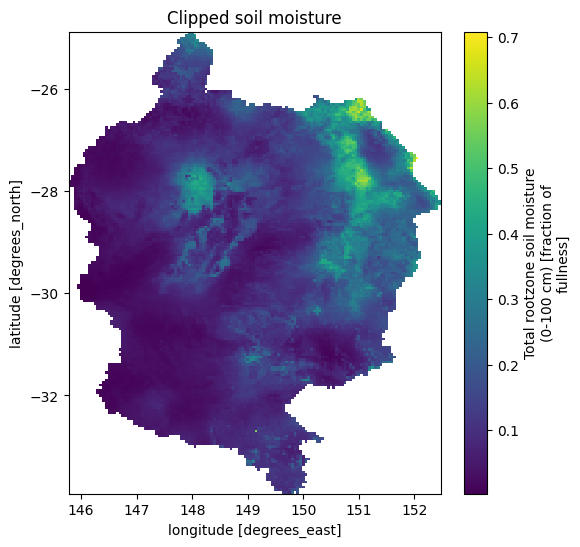

In [ ]:
# Plot clipped soil moisture

da_sm_clip.isel(time=0).plot(figsize=(6, 6))

plt.title("Clipped soil moisture")
plt.show()

In [ ]:
# Save clipped soil moisture locally

da_sm_clip = da_sm_clip.astype("float32").chunk({
    "time": 365,
    "y": 200,
    "x": 200
})

da_sm_clip.name = "soil_moisture"

local_path = "/content/soil_moisture_1981_2025_clipped.nc"

encoding = {
    "soil_moisture": {
        "zlib": True,
        "complevel": 5
    }
}

with ProgressBar():
    da_sm_clip.to_netcdf(local_path, encoding=encoding)

print("Saved locally:", local_path)

[########################################] | 100% Completed | 10m 21s
Lokal gespeichert: /content/soil_moisture_1981_2025_clipped.nc


In [ ]:
# Copy the file to Google Drive

!cp /content/soil_moisture_1981_2025_clipped.nc /content/drive/MyDrive/Raster_Data_Australia/

print("File copied to Google Drive.")

Nach Drive kopiert.


In [ ]:
print(list(ds_sm.data_vars))
print(ds_sm.dims)

['sm_pct']
FrozenMappingWarningOnValuesAccess({'time': 16436, 'latitude': 681, 'longitude': 841})


In [ ]:
# Evapotranspiration raster data

In [ ]:
!mkdir -p /content/data/et
!cp /content/drive/MyDrive/Raster_Data_Australia/ET_Raster_AUS/*.nc /content/data/et/

In [ ]:
# Check evapotranspiration files

et_files = sorted(glob.glob("/content/data/et/*.nc"))

print("Number of evapotranspiration files:", len(et_files))

et_files[:5]

Anzahl ET-Dateien: 54


['/content/data/et/etot_1972.nc',
 '/content/data/et/etot_1973.nc',
 '/content/data/et/etot_1974.nc',
 '/content/data/et/etot_1975.nc',
 '/content/data/et/etot_1976.nc']

In [ ]:
# Open one evapotranspiration file for inspection

ds_et_test = xr.open_dataset(et_files[0], engine="h5netcdf")

ds_et_test

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 366, latitude: 681, longitude: 841)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1972-01-01 1972-01-02 ... 1972-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0
Data variables:
    etot       (time, latitude, longitude) float64 2GB ...
Attributes:
    var_name:  etot

In [ ]:
# Inspect dataset structure

print(list(ds_et_test.data_vars))
print(ds_et_test.dims)
print(ds_et_test.coords)

['etot']
FrozenMappingWarningOnValuesAccess({'time': 366, 'latitude': 681, 'longitude': 841})
Coordinates:
  * time       (time) datetime64[ns] 3kB 1972-01-01 1972-01-02 ... 1972-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0


In [ ]:
# Open and combine all annual evapotranspiration files

ds_et = xr.open_mfdataset(
    et_files,
    combine="by_coords",
    engine="h5netcdf",
    parallel=False
)

ds_et

<xarray.Dataset> Size: 90GB
Dimensions:    (time: 19724, latitude: 681, longitude: 841)
Coordinates:
  * time       (time) datetime64[ns] 158kB 1972-01-01 1972-01-02 ... 2025-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0
Data variables:
    etot       (time, latitude, longitude) float64 90GB dask.array<chunksize=(32, 32, 32), meta=np.ndarray>
Attributes:
    var_name:  etot

In [ ]:
print(list(ds_et.data_vars))
print(ds_et.dims)
print(ds_et.coords)

['etot']
FrozenMappingWarningOnValuesAccess({'time': 19724, 'latitude': 681, 'longitude': 841})
Coordinates:
  * time       (time) datetime64[ns] 158kB 1972-01-01 1972-01-02 ... 2025-12-31
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0


In [ ]:
# Select the evapotranspiration variable

et_var = list(ds_et.data_vars)[0]

print("Evapotranspiration variable:", et_var)

da_et = ds_et[et_var]

Verwendete ET-Variable: etot


In [ ]:
# Rename spatial dimensions

rename_dict = {}

if "longitude" in da_et.dims:
    rename_dict["longitude"] = "x"

if "latitude" in da_et.dims:
    rename_dict["latitude"] = "y"

if rename_dict:
    da_et = da_et.rename(rename_dict)

print(da_et.dims)

('time', 'y', 'x')


In [ ]:
# Set the coordinate reference system

da_et = da_et.rio.write_crs("EPSG:4326")
da_et.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)

print(da_et.rio.crs)

EPSG:4326


In [ ]:
# Load and align the catchment boundary

shape_path = "/content/drive/MyDrive/Raster_Data_Australia/Bourke_Catchment_Area/Murray_Darling_PairwiseDisso.shp"

catchment = gpd.read_file(shape_path)
catchment = catchment.to_crs(da_et.rio.crs)

In [ ]:
# Clip evapotranspiration to the catchment

da_et_clip = da_et.rio.clip(
    catchment.geometry,
    catchment.crs,
    drop=True
)

da_et_clip

<xarray.DataArray 'etot' (time: 19724, y: 181, x: 134)> Size: 4GB
dask.array<getitem, shape=(19724, 181, 134), dtype=float64, chunksize=(32, 32, 32), chunktype=numpy.ndarray>
Coordinates:
  * time         (time) datetime64[ns] 158kB 1972-01-01 ... 2025-12-31
  * y            (y) float64 1kB -24.9 -24.95 -25.0 ... -33.8 -33.85 -33.9
  * x            (x) float64 1kB 145.8 145.8 145.9 145.9 ... 152.3 152.4 152.4
    spatial_ref  int64 8B 0
Attributes:
    name:           etot
    units:          mm
    long_name:      etot
    standard_name:  etot

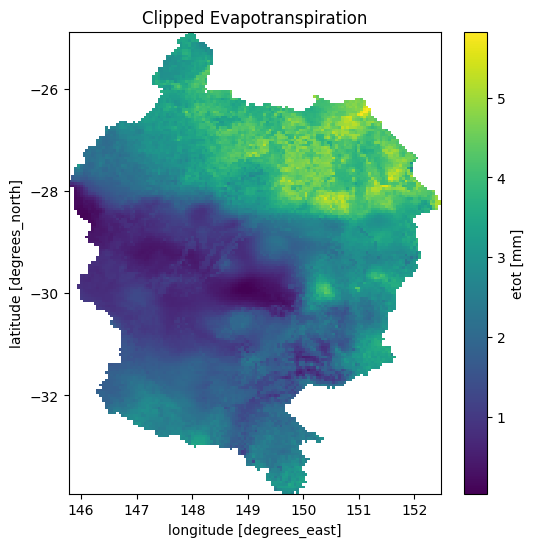

In [ ]:
# Plot clipped evapotranspiration

da_et_clip.isel(time=0).plot(figsize=(6, 6))

plt.title("Clipped evapotranspiration")
plt.show()

In [ ]:
# Save clipped evapotranspiration locally

da_et_clip = da_et_clip.astype("float32").chunk({
    "time": 365,
    "y": 200,
    "x": 200
})

da_et_clip.name = "evapotranspiration"

local_path = "/content/evapotranspiration_1972_2025_clipped.nc"

encoding = {
    "evapotranspiration": {
        "zlib": True,
        "complevel": 5
    }
}

with ProgressBar():
    da_et_clip.to_netcdf(local_path, encoding=encoding)

print("Saved locally:", local_path)

[########################################] | 100% Completed | 14m 28s
Lokal gespeichert: /content/evapotranspiration_1972_2025_clipped.nc


In [ ]:
# Copy the evapotranspiration file to Google Drive

!cp /content/evapotranspiration_1972_2025_clipped.nc /content/drive/MyDrive/Raster_Data_Australia/

print("File copied to Google Drive.")

Nach Drive kopiert.


In [ ]:
# Inspect evapotranspiration variables and dimensions

print(list(ds_et.data_vars))
print(ds_et.dims)

['etot']
FrozenMappingWarningOnValuesAccess({'time': 19724, 'latitude': 681, 'longitude': 841})
